Saving split_summary.csv to split_summary.csv


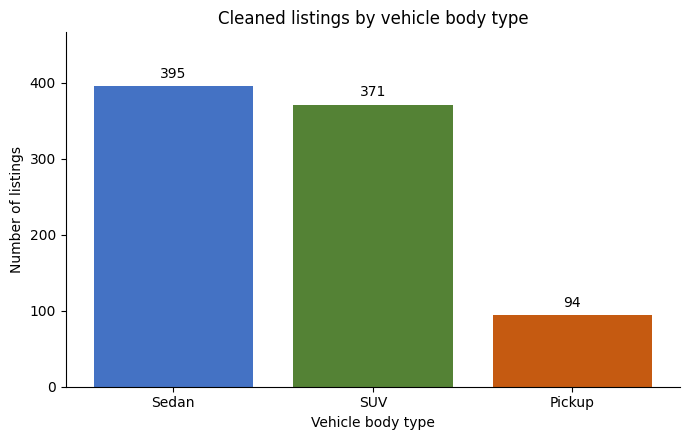

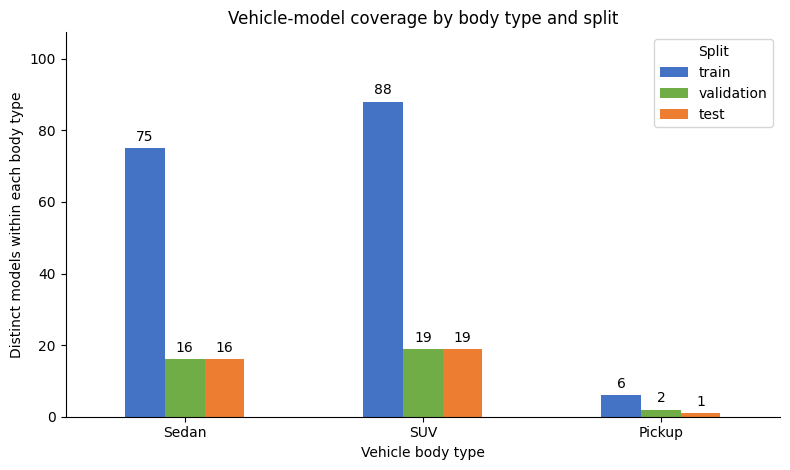

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved both figures, supporting tables, and package versions.


In [2]:
# DS 4002 Project 3 — Cleaned-data exploration
# Input: upload split_summary.csv from DVM_Cleaned_Data.zip
# Outputs: two figures, supporting tables, and package versions in OUTPUT/
# Run this cell in Google Colab.

from pathlib import Path
import io
import shutil
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from google.colab import files

# Upload the saved cleaned-data summary.
uploaded = files.upload()
if "split_summary.csv" not in uploaded:
    raise ValueError("Please upload the file named split_summary.csv.")

summary = pd.read_csv(io.BytesIO(uploaded["split_summary.csv"]))

classes = ["Sedan", "SUV", "Pickup"]
splits = ["train", "validation", "test"]

required = {"Split", "Body_type", "Listings", "Photos", "Models"}
assert required.issubset(summary.columns), "Required columns are missing."
assert not summary.duplicated(["Split", "Body_type"]).any()
assert set(summary["Split"]) == set(splits)
assert set(summary["Body_type"]) == set(classes)

output_dir = Path("OUTPUT")
output_dir.mkdir(exist_ok=True)
export_files = []

# Figure 1: representation of each body type after cleaning.
listing_counts = (
    summary.groupby("Body_type")["Listings"]
    .sum()
    .reindex(classes)
)
assert listing_counts.sum() == 860, "Unexpected total listing count."

table1 = output_dir / "cleaned_listings_by_body_type.csv"
listing_counts.rename("Listings").to_csv(table1)
export_files.append(table1)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(
    listing_counts.index,
    listing_counts.values,
    color=["#4472C4", "#548235", "#C55A11"]
)
ax.bar_label(bars, padding=4)
ax.set_title("Cleaned listings by vehicle body type")
ax.set_ylabel("Number of listings")
ax.set_xlabel("Vehicle body type")
ax.set_ylim(0, listing_counts.max() * 1.18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

figure1 = output_dir / "fig_01_cleaned_listings_by_body_type.png"
fig.savefig(figure1, dpi=200, bbox_inches="tight")
export_files.append(figure1)
plt.show()
plt.close(fig)

# Figure 2: model diversity within each body type and partition.
# A model can span body types; these are within-class model counts.
model_counts = (
    summary.pivot(index="Body_type", columns="Split", values="Models")
    .reindex(index=classes, columns=splits)
)
assert model_counts.notna().all().all(), "Missing class/split combination."

table2 = output_dir / "vehicle_models_by_body_type_and_split.csv"
model_counts.to_csv(table2)
export_files.append(table2)

ax = model_counts.plot.bar(
    figsize=(8, 4.8),
    color=["#4472C4", "#70AD47", "#ED7D31"],
    rot=0
)
for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Vehicle-model coverage by body type and split")
ax.set_xlabel("Vehicle body type")
ax.set_ylabel("Distinct models within each body type")
ax.set_ylim(0, model_counts.to_numpy().max() * 1.22)
ax.legend(title="Split")
ax.spines[["top", "right"]].set_visible(False)

fig = ax.get_figure()
fig.tight_layout()
figure2 = output_dir / "fig_02_vehicle_models_by_split.png"
fig.savefig(figure2, dpi=200, bbox_inches="tight")
export_files.append(figure2)
plt.show()
plt.close(fig)

# Record package versions.
versions = output_dir / "exploration_package_versions.txt"
versions.write_text(
    f"pandas={pd.__version__}\n"
    f"matplotlib={matplotlib.__version__}\n"
)
export_files.append(versions)

# Package only this cell's five outputs.
import zipfile

zip_path = Path("Project3_Exploration_Outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in export_files:
        archive.write(path, arcname=path.name)

files.download(str(zip_path))
print("Saved both figures, supporting tables, and package versions.")